# Paired 500-seed ablation of clustering algorithms

This notebook compares clustering algorithms inside the fixed graph-routed Atlas-DeePC pipeline. Every method uses the same offline Hankel library, six-dimensional periodic joint-configuration feature, 48 requested charts, rank-60 chart-local DeePC controller, target construction, costs, constraints, rollout length, and evaluation seeds **111 through 610**. Only the offline chart partition and the corresponding online chart-assignment rule change.

The experiment is resumable: each seed result and the cumulative `summary.json` are written immediately. Rerunning skips completed seeds.

## Interpretation boundary

K-means, spherical K-means, diagonal GMM, and affine K-subspaces are inductive algorithms with native online assignments. Agglomerative and spectral clustering are transductive, so online states are assigned to the nearest offline-cluster centroid. SSC and LRR require quadratic affinity matrices and are therefore fit on a fixed 2,000-point landmark sample; online assignment uses five-nearest-landmark voting. K-medoids uses CLARA sampling. HDBSCAN does not guarantee 48 clusters, so its density partition is deterministically merged or split to 48 charts.

These adapters make an end-to-end controller comparison possible, but the approximation class must be reported alongside performance. Any landmark cluster with fewer than 61 columns is dissolved and a large cluster is bisected so every chart can retain the frozen rank-60 controller representation; the repair count is saved in method metadata.

In [9]:
from pathlib import Path
import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import clustering_ablation_500 as benchmark

SEEDS = tuple(range(111, 611))
METHOD_ORDER = list(benchmark.METHODS)
assert SEEDS == benchmark.EVAL_SEEDS and len(SEEDS) == 500
display(pd.DataFrame.from_dict(benchmark.METHODS, orient='index').rename_axis('method key'))

,label,kind,online_assignment
method key,,,
kmeans,MiniBatch K-means,exact_inductive,nearest centroid (Euclidean)
spherical_kmeans,Spherical K-means,exact_inductive,nearest unit centroid (cosine)
gmm_diag,Diagonal Gaussian mixture,exact_inductive,maximum posterior component
agglomerative_ward,Agglomerative (Ward + k-NN connectivity),exact_offline_with_inductive_adapter,nearest offline-cluster centroid
spectral_knn,Spectral clustering (k-NN graph),exact_offline_with_inductive_adapter,nearest offline-cluster centroid
k_subspaces,Affine K-subspaces (rank 2),exact_inductive,minimum affine-subspace residual
ssc_landmark,Sparse subspace clustering (landmark),landmark_approximation,5-nearest landmark majority vote
lrr_landmark,"Low-rank representation (landmark, Frobenius n...",landmark_approximation,5-nearest landmark majority vote
kmedoids_clara,K-medoids (CLARA),sampling_approximation,nearest medoid (Euclidean)


## 1. Run or resume the experiment

The full study contains 5,000 controller rollouts and can take many hours. Leave `RUN_EXPERIMENTS=False` while analyzing partial or completed results. Set it to `True` to fit missing atlases and resume every missing seed. No completed seed is recomputed unless `force=True` is passed directly to the runner.

In [10]:
RUN_EXPERIMENTS = True
METHODS_TO_RUN = METHOD_ORDER

if RUN_EXPERIMENTS:
    for method in METHODS_TO_RUN:
        print(f'\n=== {method} ===', flush=True)
        benchmark.run_method(method, seeds=SEEDS)
else:
    print('Analysis mode. Set RUN_EXPERIMENTS=True to run/resume the 500-seed panel.')


=== kmeans ===
kmeans chart sizes 558 760.0 1292
kmeans seed 111 mean30 0.001244 success True
kmeans seed 112 mean30 0.004599 success True
kmeans seed 113 mean30 0.004479 success True
kmeans seed 114 mean30 0.003003 success True
kmeans seed 115 mean30 0.041904 success False
kmeans seed 116 mean30 0.009337 success True
kmeans seed 117 mean30 0.001676 success True
kmeans seed 118 mean30 0.001655 success True
kmeans seed 119 mean30 0.000546 success True
kmeans seed 120 mean30 0.012454 success False
kmeans seed 121 mean30 0.000971 success True
kmeans seed 122 mean30 0.003523 success True
kmeans seed 123 mean30 0.001405 success True
kmeans seed 124 mean30 0.003768 success True
kmeans seed 125 mean30 0.002531 success True
kmeans seed 126 mean30 0.001309 success True
kmeans seed 127 mean30 0.003507 success True
kmeans seed 128 mean30 0.001935 success True
kmeans seed 129 mean30 0.003647 success True
kmeans seed 130 mean30 0.003582 success True
kmeans seed 131 mean30 0.000818 success True
kme

Equivalent terminal command:

```bash
PYTHONPATH=src python src/clustering_ablation_500.py
```

A small smoke run can be launched safely with `--methods kmeans spherical_kmeans --seeds 111 --steps 10 --result-root /tmp/clustering_smoke`; nonstandard steps must never be written into the final result directory.

## 2. Load current progress

In [11]:
payloads = {}
progress_rows = []
for method in METHOD_ORDER:
    path = benchmark.RESULT_ROOT / method / 'summary.json'
    if path.exists():
        payloads[method] = json.loads(path.read_text())
        completed = {int(row['seed']) for row in payloads[method]['results']}
    else:
        completed = set()
    progress_rows.append({
        'method': method,
        'completed': len(completed & set(SEEDS)),
        'remaining': len(set(SEEDS) - completed),
        'complete': set(SEEDS) <= completed,
    })
progress = pd.DataFrame(progress_rows)
display(progress)

,method,completed,remaining,complete
0,kmeans,500,0,True
1,spherical_kmeans,500,0,True
2,gmm_diag,500,0,True
3,agglomerative_ward,500,0,True
4,spectral_knn,500,0,True
5,k_subspaces,500,0,True
6,ssc_landmark,500,0,True
7,lrr_landmark,500,0,True
8,kmedoids_clara,500,0,True
9,hdbscan_fixed_k,500,0,True


## 3. Fairness audit

Before comparing outcomes, verify that all completed methods use the frozen experimental settings and exactly the same requested panel. The method-specific fields are intentionally excluded from the invariant check.

In [12]:
INVARIANT_FIELDS = [
    'clusters', 'clustering_input_weight', 'clustering_feature_mode',
    'formulation', 'svd_rank', 'svd_bound_scale', 'negative_mass',
    'edge_count_threshold', 'target_switch_distance', 'target_matrix_mode',
    'q_xy', 'q_dq', 'q_data_goal_joint', 'r', 'lam_g', 'lam_ini',
    'lam_du', 'u_limit', 'goal_source_target_min_distance',
    'goal_branch_selection', 'steps',
]

if payloads:
    reference_method = next(iter(payloads))
    reference = payloads[reference_method]['config']
    for method, payload in payloads.items():
        config = payload['config']
        mismatches = {field: (reference[field], config[field]) for field in INVARIANT_FIELDS if reference[field] != config[field]}
        assert not mismatches, f'{method} changed frozen fields: {mismatches}'
        assert set(payload['completed_seeds']) <= set(SEEDS), f'{method} contains out-of-panel seeds'
    print(f'Frozen-field audit passed for {len(payloads)} available methods.')
else:
    print('No summaries yet.')

Frozen-field audit passed for 10 available methods.


## 4. Aggregate performance

Strict success requires both the final-30 and final-100 criteria. Confidence intervals are Wilson 95% intervals. Partial runs are shown but should not be interpreted as paired 500-seed evidence.

In [13]:
def strict_success(row):
    return bool(row['success_30'] and row['success_100'])

def wilson_interval(successes, trials, z=1.959963984540054):
    if trials == 0:
        return np.nan, np.nan
    rate = successes / trials
    denominator = 1 + z**2 / trials
    center = (rate + z**2 / (2 * trials)) / denominator
    half = z * math.sqrt(rate * (1-rate) / trials + z**2 / (4 * trials**2)) / denominator
    return center - half, center + half

result_maps = {}
aggregate_rows = []
for method, payload in payloads.items():
    rows = {int(row['seed']): row for row in payload['results'] if int(row['seed']) in SEEDS}
    result_maps[method] = rows
    flags = np.array([strict_success(row) for row in rows.values()], dtype=bool)
    successes = int(flags.sum())
    low, high = wilson_interval(successes, len(flags))
    metadata = payload['method']
    aggregate_rows.append({
        'method': method, 'label': metadata['label'], 'kind': metadata['kind'],
        'n': len(flags), 'successes': successes,
        'success rate': flags.mean() if len(flags) else np.nan,
        '95% CI low': low, '95% CI high': high,
        'mean final-30 (mm)': np.mean([1000*r['mean_last_30'] for r in rows.values()]) if rows else np.nan,
        'median final-30 (mm)': np.median([1000*r['mean_last_30'] for r in rows.values()]) if rows else np.nan,
        'mean prediction error (mm)': np.mean([1000*r['mean_prediction_error_xy'] for r in rows.values()]) if rows else np.nan,
        'median localization (ms)': np.median([r['median_localization_time_ms'] for r in rows.values()]) if rows else np.nan,
        'offline fit (s)': metadata['fit_time_s'],
    })
aggregate = pd.DataFrame(aggregate_rows)
if not aggregate.empty:
    aggregate = aggregate.sort_values(['success rate', 'mean final-30 (mm)'], ascending=[False, True])
    display(aggregate.style.format({
        'success rate': '{:.1%}', '95% CI low': '{:.1%}', '95% CI high': '{:.1%}',
        'mean final-30 (mm)': '{:.3f}', 'median final-30 (mm)': '{:.3f}',
        'mean prediction error (mm)': '{:.3f}', 'median localization (ms)': '{:.3f}',
        'offline fit (s)': '{:.1f}',
    }))
else:
    print('No benchmark results yet.')

,method,label,kind,n,successes,success rate,95% CI low,95% CI high,mean final-30 (mm),median final-30 (mm),mean prediction error (mm),median localization (ms),offline fit (s)
0,kmeans,MiniBatch K-means,exact_inductive,500,449,89.8%,86.8%,92.2%,4.375,2.098,2.135,0.063,0.7
1,spherical_kmeans,Spherical K-means,exact_inductive,500,443,88.6%,85.5%,91.1%,5.193,2.138,2.398,0.055,0.2
5,k_subspaces,Affine K-subspaces (rank 2),exact_inductive,500,435,87.0%,83.8%,89.7%,6.441,2.173,2.711,0.089,3.6
4,spectral_knn,Spectral clustering (k-NN graph),exact_offline_with_inductive_adapter,500,434,86.8%,83.6%,89.5%,5.552,2.108,2.696,0.067,25.9
2,gmm_diag,Diagonal Gaussian mixture,exact_inductive,500,430,86.0%,82.7%,88.8%,5.948,2.801,2.947,0.053,4.8
3,agglomerative_ward,Agglomerative (Ward + k-NN connectivity),exact_offline_with_inductive_adapter,500,425,85.0%,81.6%,87.9%,6.808,2.402,3.139,0.068,2.8
9,hdbscan_fixed_k,HDBSCAN projected to 48 charts,fixed_k_adapter,500,421,84.2%,80.7%,87.1%,8.919,2.418,3.491,0.064,5.3
8,kmedoids_clara,K-medoids (CLARA),sampling_approximation,500,411,82.2%,78.6%,85.3%,8.104,2.349,2.803,0.058,0.3
6,ssc_landmark,Sparse subspace clustering (landmark),landmark_approximation,500,308,61.6%,57.3%,65.8%,57.322,5.205,7.037,0.133,1.3
7,lrr_landmark,"Low-rank representation (landmark, Frobenius noise)",landmark_approximation,500,273,54.6%,50.2%,58.9%,54.880,7.944,17.243,0.129,0.9


## 5. Paired comparisons with K-means

Each comparison uses only seeds completed by both methods. The exact McNemar test is computed from discordant outcomes; the final paper table should use this section only after every method reaches 500/500.

In [14]:
paired_rows = []
if 'kmeans' in result_maps:
    baseline = result_maps['kmeans']
    for method, candidate in result_maps.items():
        if method == 'kmeans':
            continue
        common = sorted(set(baseline) & set(candidate) & set(SEEDS))
        base_flags = np.array([strict_success(baseline[s]) for s in common], dtype=bool)
        cand_flags = np.array([strict_success(candidate[s]) for s in common], dtype=bool)
        baseline_only = int(np.sum(base_flags & ~cand_flags))
        candidate_only = int(np.sum(~base_flags & cand_flags))
        discordant = baseline_only + candidate_only
        p_value = binomtest(min(baseline_only, candidate_only), discordant, p=0.5).pvalue if discordant else 1.0
        paired_rows.append({
            'method': method, 'paired n': len(common),
            'K-means only succeeds': baseline_only,
            'candidate only succeeds': candidate_only,
            'net success change': candidate_only - baseline_only,
            'exact McNemar p': p_value,
        })
paired = pd.DataFrame(paired_rows)
if not paired.empty:
    paired = paired.sort_values('net success change', ascending=False)
    display(paired.style.format({'exact McNemar p': '{:.4g}'}))
else:
    print('Paired comparisons require K-means and at least one candidate result.')

,method,paired n,K-means only succeeds,candidate only succeeds,net success change,exact McNemar p
0,spherical_kmeans,500,34,28,-6,0.5258
4,k_subspaces,500,38,24,-14,0.09795
3,spectral_knn,500,41,26,-15,0.08644
1,gmm_diag,500,58,39,-19,0.06705
2,agglomerative_ward,500,49,25,-24,0.007084
8,hdbscan_fixed_k,500,60,32,-28,0.004609
7,kmedoids_clara,500,68,30,-38,0.0001562
5,ssc_landmark,500,159,18,-141,2.182e-29
6,lrr_landmark,500,195,19,-176,5.753e-38


## 6. Visual comparison

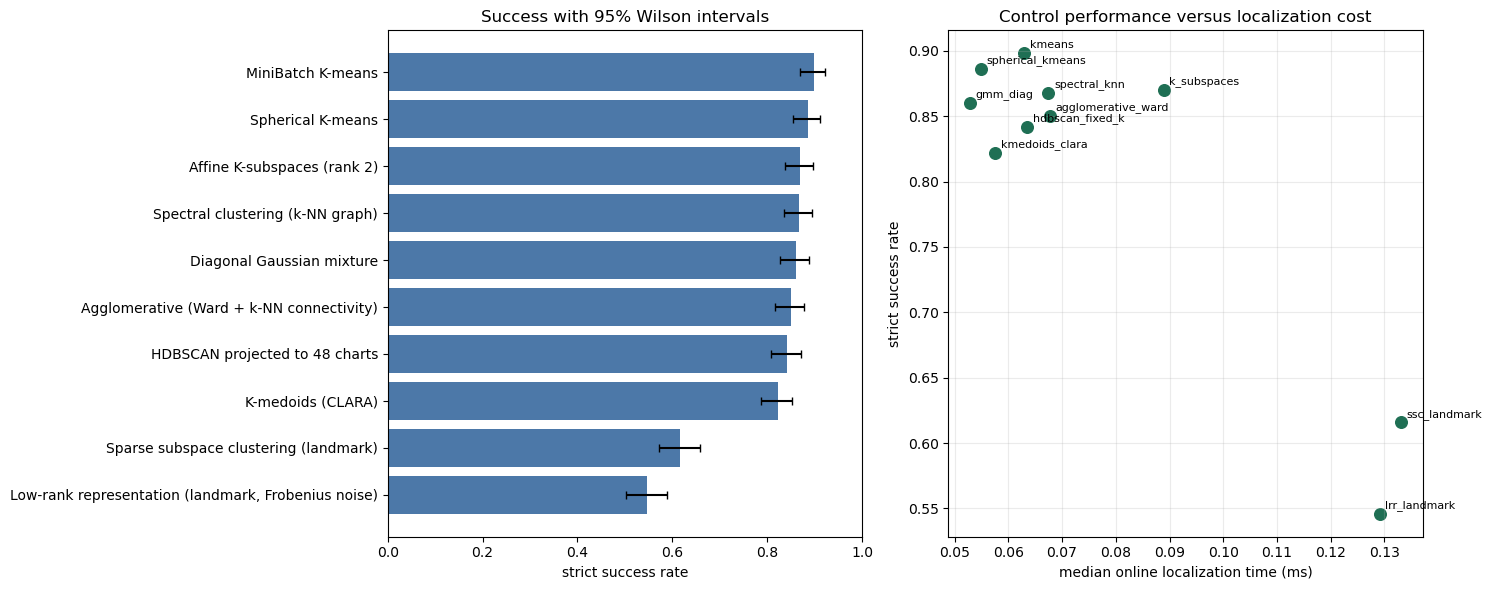

In [15]:
if not aggregate.empty:
    plot_data = aggregate.sort_values('success rate')
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    rates = plot_data['success rate'].to_numpy()
    lower = rates - plot_data['95% CI low'].to_numpy()
    upper = plot_data['95% CI high'].to_numpy() - rates
    axes[0].barh(plot_data['label'], rates, color='#4c78a8')
    axes[0].errorbar(rates, np.arange(len(plot_data)), xerr=np.vstack([lower, upper]), fmt='none', color='black', capsize=3)
    axes[0].set_xlabel('strict success rate')
    axes[0].set_xlim(0, 1)
    axes[0].set_title('Success with 95% Wilson intervals')

    axes[1].scatter(aggregate['median localization (ms)'], aggregate['success rate'], s=70, color='#1f6f54')
    for _, row in aggregate.iterrows():
        axes[1].annotate(row['method'], (row['median localization (ms)'], row['success rate']), xytext=(4, 4), textcoords='offset points', fontsize=8)
    axes[1].set_xlabel('median online localization time (ms)')
    axes[1].set_ylabel('strict success rate')
    axes[1].set_title('Control performance versus localization cost')
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

## 7. Export analysis tables

Exports are written only when all ten methods have completed the identical 500-seed panel.

In [16]:
complete = len(result_maps) == len(METHOD_ORDER) and all(set(SEEDS) <= set(rows) for rows in result_maps.values())
if complete:
    analysis_dir = benchmark.RESULT_ROOT / 'analysis'
    analysis_dir.mkdir(parents=True, exist_ok=True)
    aggregate.to_csv(analysis_dir / 'aggregate_metrics.csv', index=False)
    paired.to_csv(analysis_dir / 'paired_mcnemar_vs_kmeans.csv', index=False)
    success_matrix = pd.DataFrame({
        method: [strict_success(result_maps[method][seed]) for seed in SEEDS]
        for method in METHOD_ORDER
    }, index=pd.Index(SEEDS, name='seed'))
    success_matrix.to_csv(analysis_dir / 'per_seed_strict_success.csv')
    print('Exported final tables to', analysis_dir)
else:
    print('Not exporting final tables: the paired 500-seed panel is incomplete.')

Exported final tables to /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/clustering_methods_500/analysis


## Reporting checklist

Report strict success count/rate, paired McNemar comparison against K-means, final-30 error, one-step prediction error, offline fit time, online localization time, and chart-size distribution. Keep exact inductive methods separate from transductive adapters and landmark/sampling approximations in the main table or table notes. Do not select a winner from partial completion, and do not describe the 111–610 panel as untouched if any method or hyperparameter is changed after viewing these results.